# Norfolk County | Six shared-document questions


The [shared question document](https://docs.google.com/document/d/1Ba0FULReclAJJYfoqGe-NrArqX9EutvvRWoEKeXDgfs/edit?tab=t.0) ends with six questions for Norfolk. This notebook answers that section only.

**Coverage.** The source contains a 2017–2025 receipt cohort, or nine calendar years. The charts use that window and cannot supply a complete ten-year series. Trends by disposition year count dated outcomes in this intake cohort, so 2017 has little carry-in from earlier receipts and late cohorts can still resolve after 2025. Main outcome analyses use valid disposition dates even when receipt comes later. The chronology sensitivity restricts outcomes to dispositions on or after receipt. Receipt is a proxy for recorded intake volume where the question asks about charging. Missing stays separate from explicit unknown or other codes. Run all cells with pandas, matplotlib and IPython. Every chart is also collected into an interactive HTML dashboard at the end of the notebook.


This GitHub copy includes aggregate chart outputs. Open the figure gallery from the project README for a separate view. Local execution requires the project source extracts.

## Answers at a glance

| Question | What the Norfolk extract supports |
|---|---|
| 1. Disposition trends | Dismissals made up **67.4%** of dated DV-tagged outcome rows in 2017 and **70.3%** in 2025. For SA-tagged outcomes, the shares were **25.1%** and **26.4%**. CHAB had at most **10** eligible rows per year. The explicit child-harm charge proxy has a separate series. |
| 2. District court outcomes | Across the five district courts, the share of case-court pairs with any recorded dismissal ranged from **65.9% in Dedham** to **80.5% in Stoughton**. Case mix and missing court coverage limit comparison. |
| 3. Crime mix | **MMVE** made up **32.1%** of countywide charge rows. Agency-level mixes are available. Incident municipality is absent. |
| 4. Victims by race or ethnicity | Unavailable. Victim attributes and linkage keys are absent. |
| 5. Charging patterns | DV-tagged received cases moved from **1,726 to 1,540** between 2017 and 2025, and SA-tagged cases from **169 to 212**. Child and elder indicators are definition-sensitive. Hate-crime trends require a validated category. |
| 6. Nolle prosequi | **3,545 District** and **352 Superior** case IDs had at least one recorded NOPR charge in the window. **NARC** was the most common crime code by distinct case IDs in each court level. The notebook also shows missing court and a stricter all-observed-charges measure. |

Each figure has a corresponding CSV table under the notebook's output folder. The six results use nine years of available records and distinguish case counts from charge-row percentages.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

filename = 'NFK-Data-final-2017-2025 redacted.csv'
def find_source(name):
    """Accept the name with a space or an underscore, next to the notebook or in ./norfolk/."""
    for n in [name, name.replace(' ', '_')]:
        for p in [Path(n), Path('norfolk') / n]:
            if p.is_file():
                return p
    raise FileNotFoundError(f'Could not find {name} (or {name.replace(" ", "_")}) next to this notebook or in ./norfolk/.')
source = find_source(filename)
sha256 = hashlib.sha256(source.read_bytes()).hexdigest()
raw = pd.read_csv(source, encoding='cp1252', dtype=str, keep_default_na=False)
d = raw.apply(lambda s: s.str.strip().replace('', 'Missing'))
d['record'] = d.index + 1  # One-based data-record ordinal after header.
YEARS = list(range(2017, 2026))
for field, alias, fmt in [
    ('Received Date','received','%m/%d/%Y'),
    ('Date Crm','offense','%Y-%m-%d %I:%M%p'),
    ('Date Dspstn','disposed','%Y-%m-%d %I:%M%p'),
    ('Date Exctn','execution','%Y-%m-%d %I:%M%p')
]:
    parsed = pd.to_datetime(d[field], format=fmt, errors='coerce')
    valid = parsed.between('1900-01-01','2026-11-06')
    d[alias] = parsed.where(valid)
    d[alias+'_quality'] = 'Valid'
    d.loc[d[field].eq('Missing'), alias+'_quality'] = 'Missing'
    d.loc[d[field].ne('Missing') & ~valid, alias+'_quality'] = 'Invalid / out of bounds'

d['received_year'] = d.received.dt.year.astype('Int64')
d['disposed_year'] = d.disposed.dt.year.astype('Int64')
d['disposition'] = d['Desc Dspstn']
cwof = d['Code Dspstn'].eq('PLEA') & d['Code Rsn Dspstn'].eq('CWOF')
d.loc[cwof,'disposition'] = 'CWOF (plea reason)'
d.loc[d['Code Dspstn'].eq('PLEA') & ~cwof,'disposition'] = 'Other recorded plea'
d['days_offense_received'] = (d.received - d.offense).dt.days
d['days_received_disposition'] = (d.disposed - d.received).dt.days
d['days_offense_disposition'] = (d.disposed - d.offense).dt.days
court_names = {'QDC':'Quincy', 'BDC':'Brookline', 'DDC':'Dedham',
               'SDC':'Stoughton','WDC':'Wrentham','NSC':'Norfolk Superior'}
d['court'] = d['Code Crt Lctn Disp'].map(court_names).fillna(d['Code Crt Lctn Disp'])
d['court_level'] = 'Other / unmapped'
d.loc[d.court.isin(list(court_names.values())[:5]),'court_level'] = 'District'
d.loc[d.court.eq('Norfolk Superior'),'court_level'] = 'Superior'
d.loc[d.court.eq('Missing'),'court_level'] = 'Missing'
window = d[d.disposed_year.isin(YEARS) & d['Code Dspstn'].ne('Missing')].copy()
chronological = window[window.days_received_disposition.ge(0)].copy()
cohort = d[d.received_year.isin(YEARS)].copy()
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
palette = ['#27647b','#dc8951','#719b81','#845e91','#b7575c','#8a8f98',
           '#a9b9c5','#9e7948','#434979','#72714b','#a87caa','#456a52']
STATIC_CHARTS = True   # keep matplotlib PNGs (GitHub preview); the dashboard is built at the end
SPECS = []             # one entry per chart, consumed by the interactive dashboard cell
def _num(x):
    try:
        return None if pd.isna(x) else (int(x) if float(x).is_integer() else round(float(x), 4))
    except (TypeError, ValueError):
        return None
def register(data, title, ylabel, kind='bar', stacked=False, q=None, counts=None, denom=None,
             denom_label='', meta='', finding='', notes='', cat_label='', color_group=None, focus=None):
    """Store a chart's data, counts and denominators for the interactive dashboard."""
    frame = data.to_frame() if isinstance(data, pd.Series) else data.copy()
    if counts is not None:
        counts = counts.to_frame(frame.columns[0]) if isinstance(counts, pd.Series) else counts
        counts = counts.reindex(index=frame.index, columns=frame.columns)
    js_kind = kind if kind in ('line','barh','dot') else 'stacked' if stacked else 'grouped'
    if focus is not None and focus in frame.columns:        # focus series first = bottom of the stack
        order = [focus] + [c for c in frame.columns if c != focus]
        frame = frame[order]
        counts = None if counts is None else counts[order]
    if js_kind == 'barh':                       # largest bar on top in the browser
        frame = frame.iloc[::-1]
        counts = None if counts is None else counts.iloc[::-1]
    cats = [str(c) for c in frame.index]
    is_year = all(str(c).isdigit() and 1900 < int(c) < 2100 for c in frame.index)
    unit = 'pct' if 'percent' in ylabel.lower() else 'count'
    sdenom = None
    if isinstance(denom, dict):
        sdenom, denom = {str(k): _num(v) for k, v in denom.items()}, None
    elif denom is not None and not hasattr(denom, '__len__'):
        denom = [denom] * len(frame)
    elif denom is not None:
        denom = pd.Series(denom).reindex(frame.index)
    SPECS.append(dict(
        id=f"chart_{len(SPECS)+1:02d}", q=q, colorGroup=color_group,
        focus=focus if focus is not None else (str(frame.columns[0]) if js_kind == 'stacked' else None), title=title, ylabel=ylabel, kind=js_kind, unit=unit,
        categories=cats, isYear=is_year, catLabel=cat_label, meta=meta, finding=finding, notes=notes,
        hasCounts=counts is not None or unit == 'count', denomLabel=denom_label, sdenom=sdenom,
        denom=None if denom is None else [_num(v) for v in denom],
        series=[dict(name=str(col), value=[_num(v) for v in frame[col]],
                     count=None if counts is None else [_num(v) for v in counts[col]])
                for col in frame.columns]))
def chart(data, title, ylabel, kind='bar', stacked=False, xlabel='', figsize=(10,4), **dash):
    register(data, title, ylabel, kind, stacked, **dash)
    if not STATIC_CHARTS:
        return
    ax = data.plot(kind='barh' if kind == 'dot' else kind, stacked=stacked, figsize=figsize, color=palette)
    ax.set(title=title, ylabel=ylabel, xlabel=xlabel)
    if kind == 'bar':
        ax.tick_params(axis='x', labelrotation=0)
    if ax.get_legend():
        ax.legend(bbox_to_anchor=(1.02,1), loc='upper left', title=None, fontsize=8)
    plt.tight_layout()
    plt.show()
    plt.close(ax.figure)
def table(frame, name, limit=16):
    frame.to_csv(out / (name + '.csv'))
    display(frame.head(limit).round(2))
def mix(frame, by, value, name, title, top=7, **dash):
    frequent = frame[value].value_counts().head(top).index.union(['Missing'], sort=False)
    shown = frame[value].where(frame[value].isin(frequent), 'Other recorded')
    counts = pd.crosstab(frame[by], shown)
    pct = counts.div(counts.sum(axis=1),axis=0).mul(100)
    table(pd.crosstab(frame[by],frame[value]),name+'_full_counts')
    table(pct,name+'_chart_pct')
    order = [c for c in shown.value_counts().index if c not in ('Other recorded','Missing')]
    order += [c for c in ('Other recorded','Missing') if c in counts]
    counts, pct = counts[order], pct[order]
    dash.setdefault('denom', counts.sum(axis=1))
    dash.setdefault('denom_label', 'rows')
    chart(pct,title,'Percent of rows',stacked=True,counts=counts,**dash)
def summary_days(x):
    usable = x[x.ge(0)]
    return pd.Series({'all_rows':len(x),'missing_or_invalid':x.isna().sum(),
                      'negative':x.lt(0).sum(),'usable':len(usable),
                      'mean':usable.mean(),'p25':usable.quantile(.25),
                      'median':usable.median(),'p75':usable.quantile(.75),
                      'p95':usable.quantile(.95),'max':usable.max()})

out = source.parent / 'norfolk_questions_outputs'
out.mkdir(exist_ok=True)

## Definitions used across questions
DV and SA are source **case-type** tags, so their series include accompanying charges. CHAB, ELAB and HACR are **crime-type** codes whose meanings need codebook confirmation. A second series uses named charge codes or descriptions as narrower checks. The cohorts can overlap and must not be added together.

In [2]:
desc = d['Desc Chrg'].str.upper()
charge = d['Code Chrg']
case_type = d['Case Type']
crime = d['Crime Type']
groups = {
    'DV case tag': case_type.eq('DV'),
    'SA case tag': case_type.eq('SA'),
    'CHAB crime code': crime.eq('CHAB'),
    'ELAB crime code': crime.eq('ELAB'),
    'HACR crime code (unverified)': crime.eq('HACR'),
    'Family / household charge': desc.str.contains(r'FAMILY\s*/\s*HOUSEHOLD'),
    'RAPE or INDO crime code': crime.isin(['RAPE','INDO']),
    'Explicit child harm charge proxy': charge.str.startswith(('265/13J','265/13L','119/39')),
    'Elder / disabled charge proxy': charge.str.startswith('265/13K'),
    'Civil-rights charge proxy': charge.str.startswith(('265/37','12/11J'))
}
audit = []
for group, mask in groups.items():
    g = d.loc[mask]
    display(Markdown(f'**{group}** — {len(g):,} rows in {g["Id Cs"].nunique():,} distinct cases.'))
    for (code, description), n in g.groupby(['Code Chrg','Desc Chrg']).size().items():
        audit.append((group,code,description,n))
table(pd.DataFrame(audit,columns=['definition','charge_code','description','rows'])
      .sort_values(['definition','rows'],ascending=[True,False]),'category_definition_audit',10)
display(d.loc[groups['HACR crime code (unverified)'],'Desc Chrg'].value_counts().to_frame('rows'))

## 1. How have dispositions for domestic violence, sexual assault, and child abuse changed?

**Partially answerable.** Compare recorded charge outcomes within the DV and SA case tags and the CHAB crime code. A CHAB row is a source coding signal, and an explicit child-harm charge proxy provides a definition check. The outcome denominator is qualifying charge rows within each group and disposition year. All outcome categories are exported. The charts pool rare labels under Other recorded and display annual denominators separately. Small CHAB denominators can move the percentages substantially.

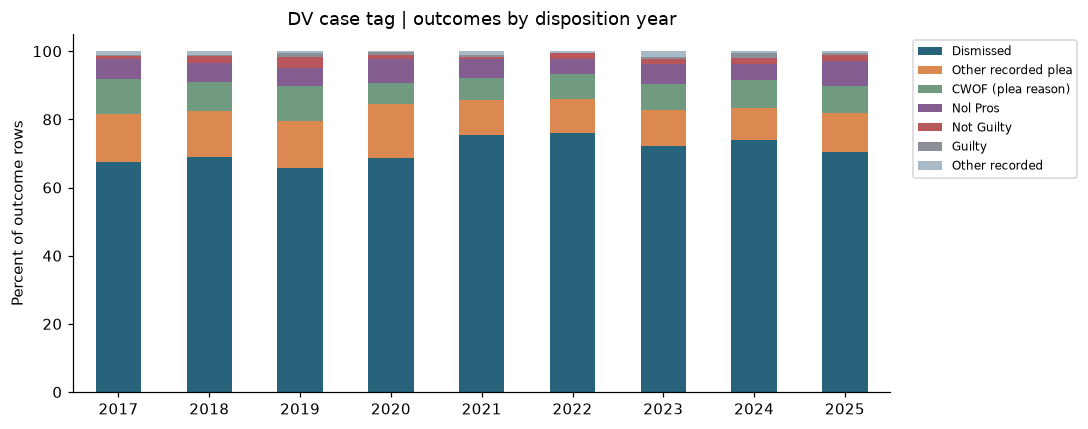

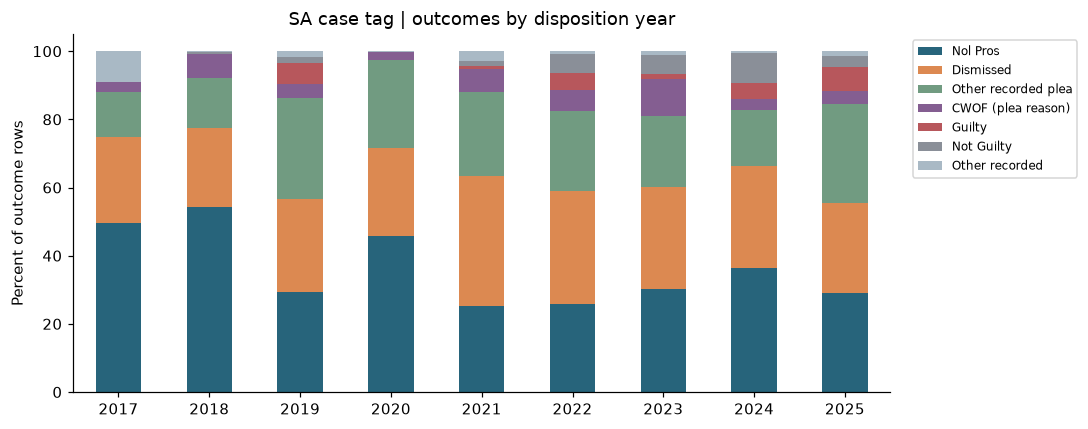

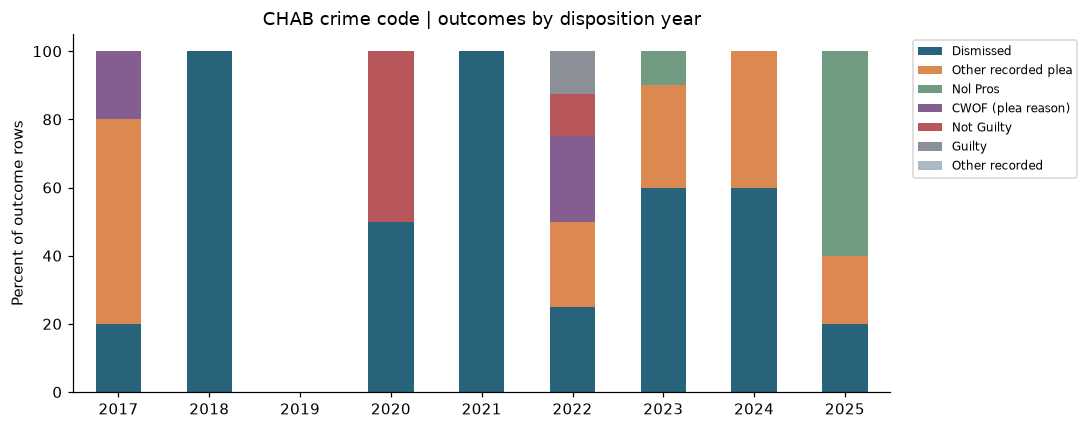

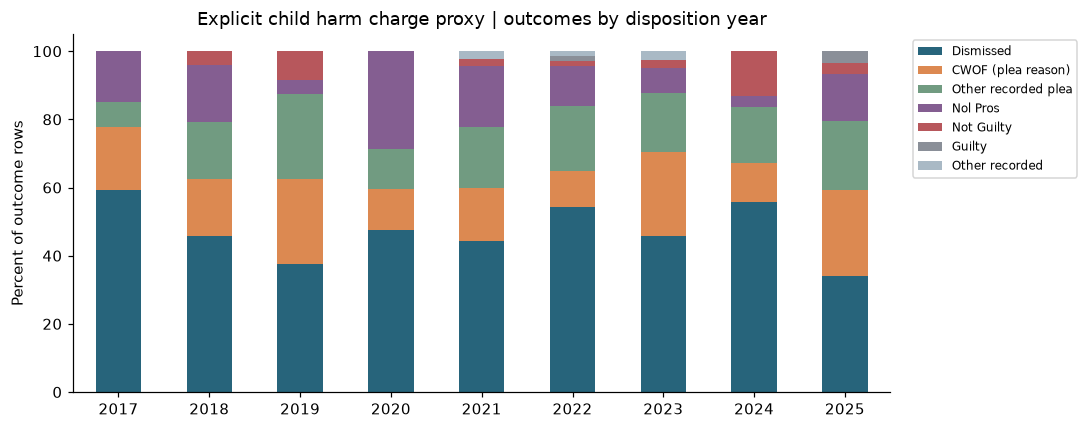

In [3]:
for name in ['DV case tag','SA case tag','CHAB crime code','Explicit child harm charge proxy']:
    selected = window.loc[groups[name].reindex(window.index)]
    key = name.split()[0].lower()
    counts = pd.crosstab(selected.disposed_year,selected.disposition).reindex(YEARS,fill_value=0)
    table(counts,'q1_'+key+'_outcome_counts',10)
    n = counts.sum(axis=1)
    leading = list(counts.sum().nlargest(6).index)
    shown = counts[leading].copy()
    shown['Other recorded'] = n - shown.sum(axis=1)
    pct = shown.div(n.where(n.gt(0)),axis=0).mul(100)
    table(pct,'q1_'+key+'_outcome_pct',10)
    comparison = n.to_frame('eligible_rows')
    # Keep the same outcome labels for the chronology sensitivity.
    timed = selected[selected.days_received_disposition.ge(0)]
    timed_counts = pd.crosstab(timed.disposed_year,timed.disposition).reindex(
        index=YEARS,columns=counts.columns,fill_value=0)
    comparison['rows_disposition_on_or_after_receipt'] = timed_counts.sum(axis=1)
    table(timed_counts,'q1_'+key+'_chronology_sensitivity_counts',10)
    finding = ''
    if 'Dismissed' in counts and n.loc[2017] and n.loc[2025]:
        finding = (f"Dismissed share: {counts.at[2017,'Dismissed']/n.loc[2017]:.1%} in 2017 and "
                   f"{counts.at[2025,'Dismissed']/n.loc[2025]:.1%} in 2025.")
        print(finding)
    print(f"Annual outcome denominators range from {n.min():,} to {n.max():,} rows.")
    short = {'DV case tag':'DV cases','SA case tag':'SA cases','CHAB crime code':'CHAB-coded charges',
             'Explicit child harm charge proxy':'Child-harm charges'}[name]
    headline = f'{short}: outcomes by disposition year'
    if n.min() < 30:
        headline = f'{short}: only {n.min():,}–{n.max():,} outcome rows a year, too few for stable percentages'
    elif 'Dismissed' in pct and pd.notna(pct.at[2017,'Dismissed']) and pd.notna(pct.at[2025,'Dismissed']):
        a, z = pct.at[2017,'Dismissed'], pct.at[2025,'Dismissed']
        verb = 'rose' if z - a >= 1 else 'fell' if a - z >= 1 else 'held steady'
        headline = (f'{short}: dismissals {verb} from {a:.0f}% to {z:.0f}% of outcomes' if verb != 'held steady'
                    else f'{short}: dismissals held near {z:.0f}% of outcomes, 2017–2025')
    chart(pct,headline,'Percent of outcome rows',stacked=True,
          q='1',color_group='outcomes',focus='Dismissed' if 'Dismissed' in pct else None,counts=shown,denom=n,denom_label='outcome rows',cat_label='Disposition year',
          meta=f'{name}. Charge outcome rows per disposition year. Annual denominators {n.min():,} to {n.max():,}.')
    table(comparison,'q1_'+key+'_denominators')

## 2. How do outcomes vary across Quincy, Brookline, Dedham, Stoughton and Wrentham?

**Answerable descriptively for the recorded cohort.** Use the recorded disposition location and inferred abbreviation mapping. Show charge outcomes, plus the share of case-court pairs with each selected outcome. A pair may have multiple outcomes and a case may appear at multiple courts. Rates are unadjusted for case mix. Missing court stays visible and court may be recorded differently across charges in the same case.

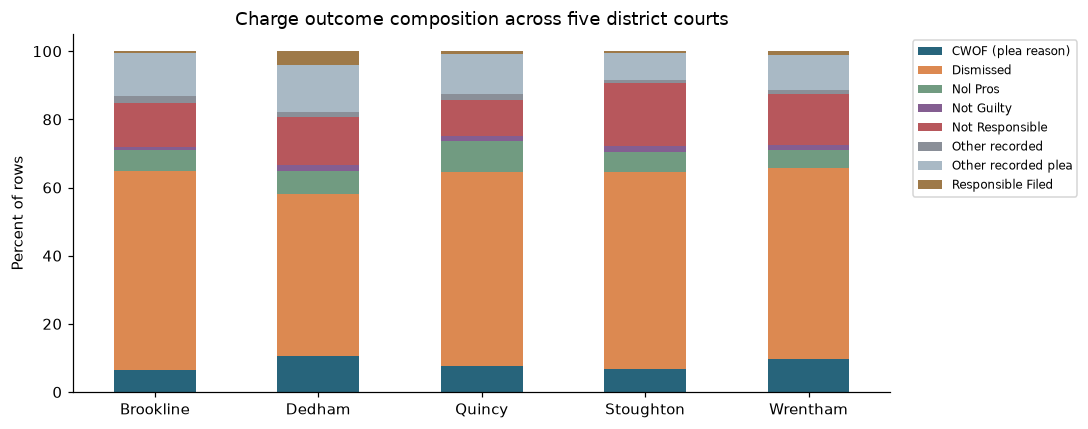

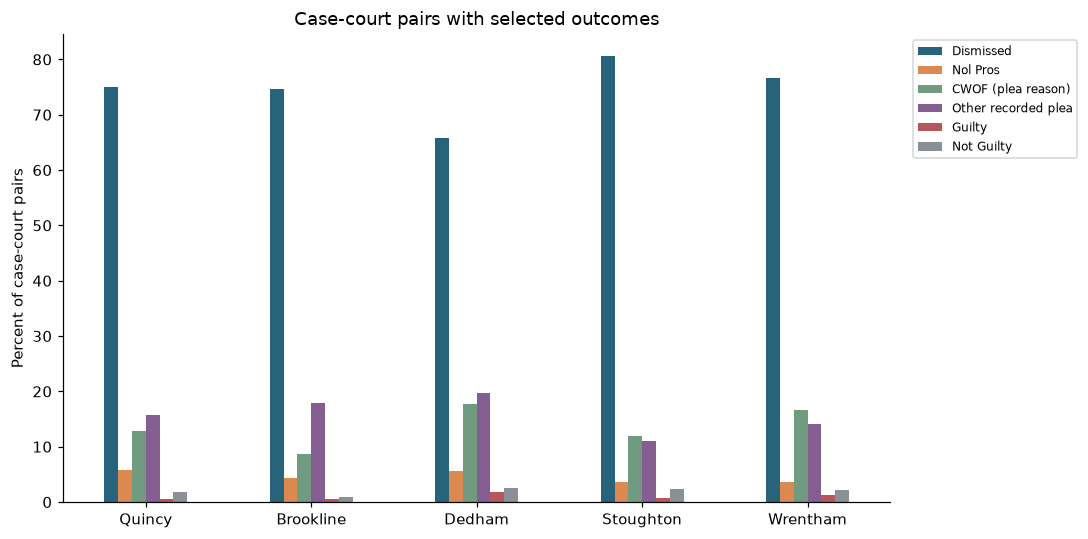

In [4]:
court_counts = pd.crosstab(window.court,window.disposition)
table(court_counts,'q2_charge_outcome_counts')
table(pd.crosstab(chronological.court,chronological.disposition),'q2_chronology_sensitivity_counts')
named = window[window.court_level.eq('District')]
_dz = pd.crosstab(named.court, named.disposition, normalize='index').mul(100).get('Dismissed', pd.Series(dtype=float))
_t2 = (f'Dismissals are {_dz.min():.0f}–{_dz.max():.0f}% of charge outcomes in every district court'
       if len(_dz) else 'Charge outcome composition across five district courts')
mix(named,'court','disposition','q2_district',_t2,
    q='2',color_group='outcomes',focus='Dismissed',denom_label='charge outcome rows',cat_label='Court',meta='Charge outcome composition across five district courts. Top labels shown, rest pooled.')
pairs = window[['Id Cs','court','disposition']].drop_duplicates()
den = pairs.groupby('court')['Id Cs'].nunique()
case_counts = pd.crosstab(pairs.court,pairs.disposition)
case_rates = case_counts.div(den,axis=0).mul(100)
table(case_rates.join(den.rename('case_court_pairs')),'q2_case_court_any_outcome_pct')
primary = ['Dismissed','Nol Pros','CWOF (plea reason)','Other recorded plea','Guilty','Not Guilty']
district_rates = case_rates.reindex(list(court_names.values())[:5])
dismissed = district_rates['Dismissed']
finding = (f"Any dismissal ranged from {dismissed.min():.1f}% in {dismissed.idxmin()} "
           f"to {dismissed.max():.1f}% in {dismissed.idxmax()}.")
print(finding)
chart(district_rates[primary].T,
      f'Any dismissal: {dismissed.min():.0f}% in {dismissed.idxmin()} to {dismissed.max():.0f}% in {dismissed.idxmax()}',
      'Percent of case-court pairs',figsize=(10,5),kind='dot',
      q='2',color_group='courts',counts=case_counts.reindex(district_rates.index)[primary].T,
      denom=den.reindex(district_rates.index).to_dict(),denom_label='case-court pairs',cat_label='Outcome',
      meta='Share of case-court pairs with each outcome; one dot per court. Pairs can have several outcomes. Unadjusted for case mix.')

## 3. What is the breakdown of crime types by municipality and countywide?

**County extract answerable. Municipality unavailable.** The county table measures the composition of recorded charge rows by source crime-type code. The agency table gives a separate administrative breakdown. Police agencies can handle incidents across borders, and State Police and other agencies cannot be assigned to incident municipalities from these fields. This extract measures recorded prosecution activity rather than all incidents.

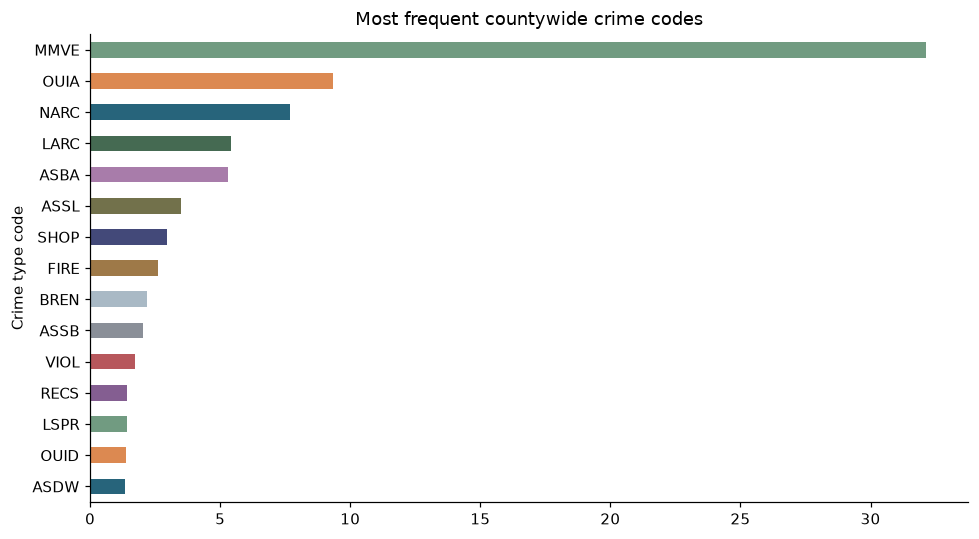

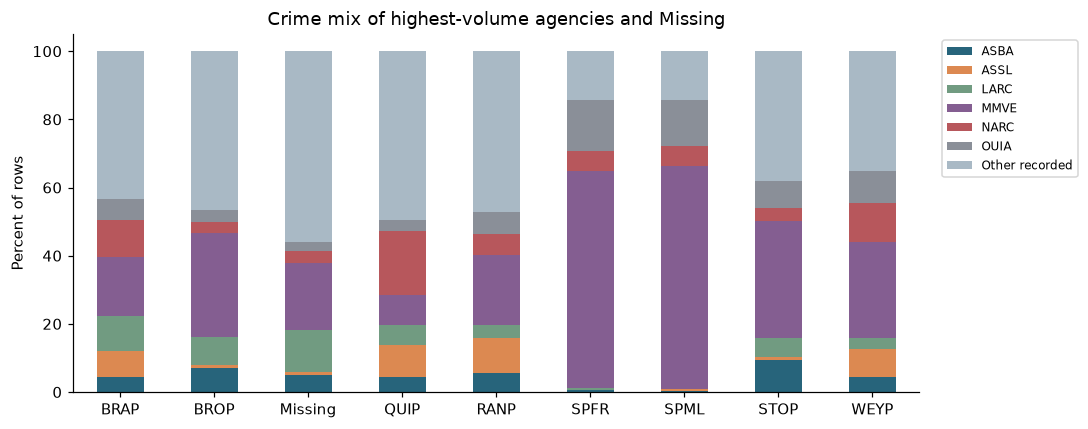

In [5]:
county = cohort['Crime Type'].value_counts().rename('charge_rows').to_frame()
county['percent_of_charge_rows'] = county.charge_rows / len(cohort) * 100
table(county,'q3_county_crime_mix',20)
top15 = county.head(15).sort_values('percent_of_charge_rows')
chart(top15.percent_of_charge_rows.rename('Share of charge rows'),
      f"{county.index[0]} accounts for {county.percent_of_charge_rows.iloc[0]:.0f}% of all charge rows countywide",
      'Percent of charge rows',kind='barh',figsize=(9,5),q='3',counts=top15.charge_rows,
      denom=len(cohort),denom_label='charge rows in cohort',cat_label='Crime code',
      meta='Most frequent countywide crime codes (top 15), receipt cohort.')
agency_counts = pd.crosstab(cohort['Code Ofcr Agncy'],cohort['Crime Type'])
agency_pct = agency_counts.div(agency_counts.sum(axis=1),axis=0).mul(100)
table(agency_counts,'q3_agency_crime_counts',6)
table(agency_pct.join(agency_counts.sum(axis=1).rename('all_agency_rows')),
      'q3_agency_crime_pct',6)
top_agencies = agency_counts.sum(axis=1).drop('Missing').nlargest(8).index.union(['Missing'],sort=False)
_ag = cohort[cohort['Code Ofcr Agncy'].isin(top_agencies)]
_lead = pd.crosstab(_ag['Code Ofcr Agncy'], _ag['Crime Type']).idxmax(axis=1)
_t3 = (f'{_lead.iloc[0]} is the largest crime category at all {len(_lead)} agencies shown' if _lead.nunique() == 1
       else f'The largest crime category differs across agencies ({", ".join(sorted(_lead.unique()))})')
mix(_ag,'Code Ofcr Agncy','Crime Type','q3_top_agencies',_t3,6,
    q='3',cat_label='Agency',meta='Crime mix of the eight highest-volume officer agencies plus Missing. Agencies are not municipalities.')

## 4. What is the breakdown of victims by race/ethnicity, overall and over time?

**Unavailable.** The CSV has no victim ID, victim role, or victim race/ethnicity field. The person race code appears on the prosecution record. Victim-level trends would need a victim-level dataset with time coverage and a victim linkage key.

## 5. How have charging patterns changed for DV, sexual assault, child abuse, elder abuse, and hate crimes?

**Partially answerable.** Compare annual case counts, charge rows, and shares of all recorded receipts. This is the observed charge inventory grouped by receipt year. There is no original-charge history or confirmed filing date.

The DV/SA case tags are broad. CHAB and ELAB are provisional code indicators and include a range of charge descriptions. The elder charge proxy combines elder and disabled wording, so elder-only totals remain unavailable. HACR occurs alongside a habitual-offender charge description. That could be an enhancement within a flagged matter, but the code meaning and bias motivation are unverified. Civil-rights charges are a separate observable proxy. A defensible hate-crime trend requires a verified definition and code mapping.

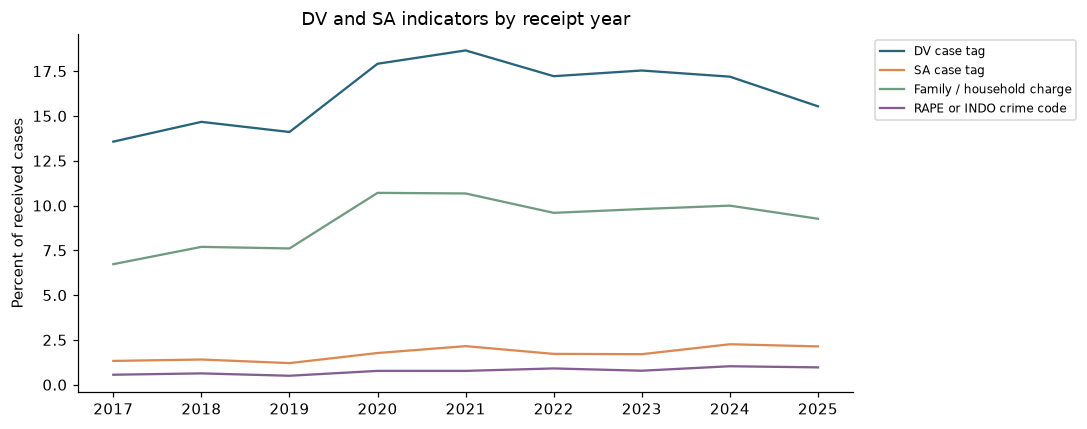

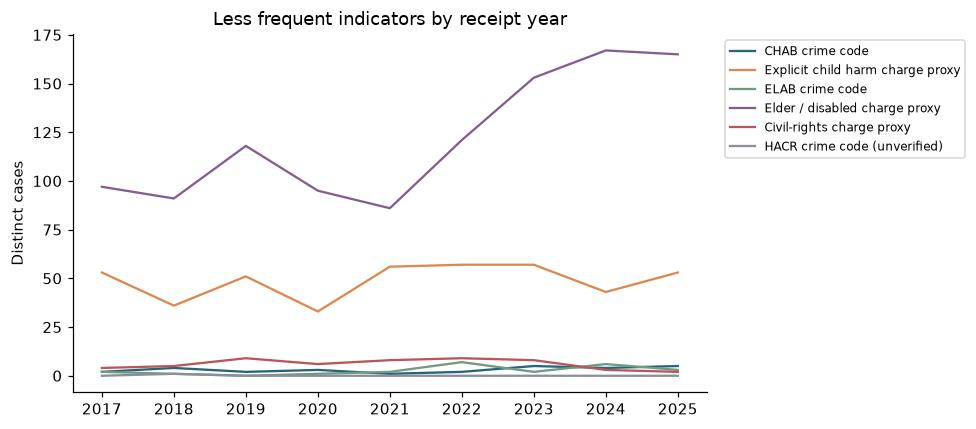

In [6]:
base = cohort.groupby('received_year').agg(all_rows=('record','size'),all_cases=('Id Cs','nunique'))
pieces = []
for name, mask in groups.items():
    sub = cohort.loc[mask.reindex(cohort.index)]
    a = sub.groupby('received_year').agg(charge_rows=('record','size'),cases=('Id Cs','nunique'))
    a = a.reindex(YEARS,fill_value=0).join(base)
    a['charge_share_pct'] = a.charge_rows / a.all_rows * 100
    a['case_share_pct'] = a.cases / a.all_cases * 100
    pieces.append(a.assign(group=name))
annual_groups = pd.concat(pieces).rename_axis('year').reset_index()
table(annual_groups.set_index(['group','year']),'q5_annual_receipt_cohorts',18)
p = annual_groups.pivot(index='year',columns='group',values='cases')
table(p,'q5_case_counts_for_all_definitions',10)
for indicator in ['DV case tag','SA case tag','CHAB crime code','ELAB crime code',
                  'Explicit child harm charge proxy','Elder / disabled charge proxy']:
    print(f"{indicator}: {p.at[2017,indicator]:,} cases in 2017 and {p.at[2025,indicator]:,} in 2025.")
shares = annual_groups.pivot(index='year',columns='group',values='case_share_pct')
dvsa = ['DV case tag','SA case tag','Family / household charge','RAPE or INDO crime code']
_a, _z = p.at[2017,'DV case tag'], p.at[2025,'DV case tag']
chart(shares[dvsa],f"DV-tagged cases went from {_a:,} in 2017 to {_z:,} in 2025 ({(_z/_a-1)*100:+.0f}%)" if _a else 'DV and SA indicators by receipt year',
      'Percent of received cases',kind='line',
      q='5',counts=p[dvsa],denom=base.all_cases.reindex(YEARS),denom_label='received cases',
      cat_label='Receipt year',meta='DV and SA indicators: share of all received cases carrying each tag. Definitions overlap; do not add.')
chart(p[['CHAB crime code','Explicit child harm charge proxy','ELAB crime code',
         'Elder / disabled charge proxy','Civil-rights charge proxy','HACR crime code (unverified)']],
      f"Less frequent indicators stay at or below {int(p[['CHAB crime code','Explicit child harm charge proxy','ELAB crime code','Elder / disabled charge proxy','Civil-rights charge proxy','HACR crime code (unverified)']].max().max()):,} cases a year",
      'Distinct cases',kind='line',figsize=(9,4),
      q='5',cat_label='Receipt year',meta='Less frequent indicators: distinct cases per receipt year. CHAB, ELAB and HACR meanings need codebook confirmation.')

## 6. What is the nolle prosequi case breakdown by crime type in District and Superior Court?

**Answerable for the observed window.** Use the source code NOPR, labeled Nol Pros. A case qualifies in a court level if at least one eligible charge in that level received NOPR. Assign crime types from those NOPR charges. The same case can appear under several crime types or both court levels, so case percentages across types may sum above 100%. Charge composition has a separate denominator and sums to 100% within each level. Missing and unmapped courts stay separate.

The all-observed-outcomes sensitivity counts case-level pairs whose eligible charges all received NOPR. Restrict that calculation to source DISP cases without a recorded post-window disposition or outcome-bearing rows outside the eligible set, and require all recorded case charge rows to be eligible and in the same level. Even this stricter rule is limited to observed rows.

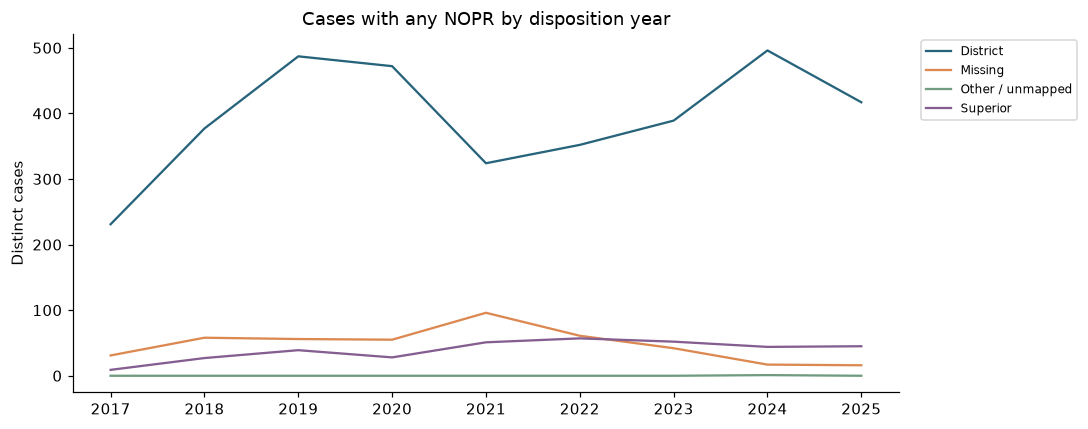

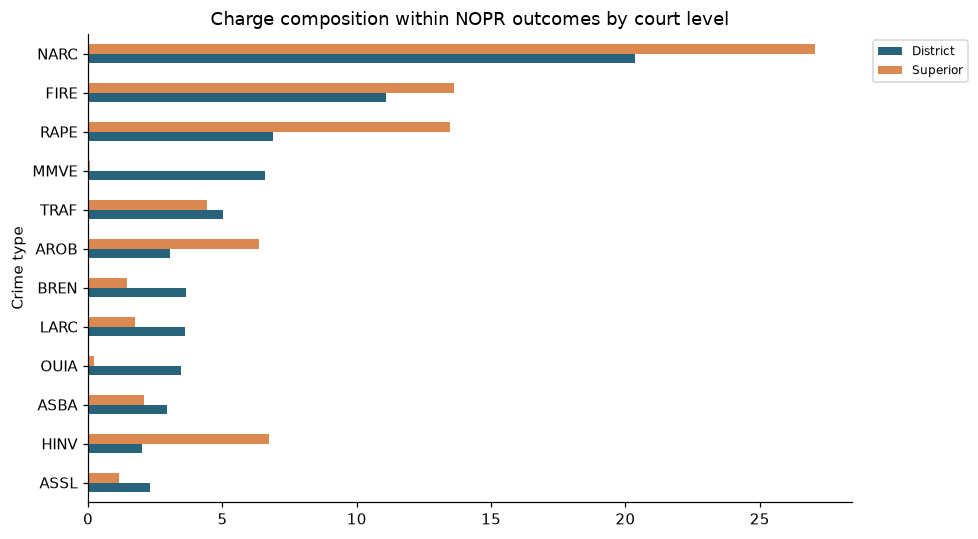

In [7]:
nop = window[window['Code Dspstn'].eq('NOPR')]
level = nop.groupby('court_level').agg(nopr_charge_rows=('record','size'),nopr_cases=('Id Cs','nunique'))
type_mix = nop.groupby(['court_level','Crime Type']).agg(nopr_charge_rows=('record','size'),
                                                           nopr_cases=('Id Cs','nunique'))
type_mix = type_mix.join(level.add_prefix('level_'),on='court_level')
type_mix['charge_pct'] = type_mix.nopr_charge_rows / type_mix.level_nopr_charge_rows * 100
type_mix['case_pct_overlapping_types'] = type_mix.nopr_cases / type_mix.level_nopr_cases * 100
table(level,'q6_totals_by_level')
table(nop[nop.days_received_disposition.ge(0)].groupby('court_level').agg(
    nopr_charge_rows=('record','size'),nopr_cases=('Id Cs','nunique')),
    'q6_chronology_sensitivity_totals')
q6_findings = []
for level_name in ['District','Superior']:
    highest = type_mix.loc[level_name].sort_values('nopr_cases',ascending=False).iloc[0]
    q6_findings.append(f"{level_name}: {level.at[level_name,'nopr_cases']:,} cases with any NOPR. "
                       f"Leading crime code {highest.name}, {highest.nopr_cases:,.0f} cases "
                       f"({highest.case_pct_overlapping_types:.1f}%).")
    print(q6_findings[-1])
table(type_mix.sort_values(['court_level','nopr_cases'],ascending=[True,False]),
      'q6_crime_type_breakdown',22)
table(nop.groupby(['disposed_year','court_level','Crime Type']).agg(
      rows=('record','size'),cases=('Id Cs','nunique')),'q6_year_level_type')
level_year = nop.groupby(['disposed_year','court_level'])['Id Cs'].nunique().unstack(fill_value=0)
table(level_year,'q6_distinct_cases_by_year_and_level')
_ly = level_year.reindex(YEARS,fill_value=0)
_dist = _ly['District'] if 'District' in _ly else pd.Series(0,index=YEARS)
chart(_ly,f'District cases with a nolle prosequi: {_dist.loc[2017]:,} in 2017, {_dist.loc[2025]:,} in 2025','Distinct cases',kind='line',
      q='6',cat_label='Disposition year',finding=' '.join(q6_findings),
      meta='Cases with any NOPR by disposition year: distinct case IDs with at least one NOPR charge, by court level.')
leading = nop[nop.court_level.isin(['District','Superior'])]['Crime Type'].value_counts().head(12).index
shown = type_mix.charge_pct.unstack('court_level').reindex(leading)[['District','Superior']].fillna(0)
shown_counts = type_mix.nopr_charge_rows.unstack('court_level').reindex(leading)[['District','Superior']].fillna(0)
_top = {lv: type_mix.loc[lv].charge_pct.idxmax() for lv in ['District','Superior']}
chart(shown.iloc[::-1],(f"{_top['District']} is the most common crime code among NOPR charges in both courts"
      if _top['District'] == _top['Superior'] else 'Charge composition within NOPR outcomes by court level'),
      'Percent of NOPR charge rows',kind='barh',figsize=(9,5),q='6',counts=shown_counts.iloc[::-1],
      denom={lv: level.at[lv,'nopr_charge_rows'] for lv in ['District','Superior']},cat_label='Crime code',
      meta='Charge composition within NOPR outcomes. Each court level sums to 100% across all crime codes; 12 most common shown.')
all_raw = d.groupby('Id Cs').size()
strict = nop.groupby(['Id Cs','court_level']).agg(rows=('record','size'),status=('Case Status','first'))
strict = strict[strict.status.eq('DISP') & strict.rows.eq(strict.index.get_level_values('Id Cs').map(all_raw))]
table(strict.groupby('court_level').size().rename('cases_all_source_rows_eligible_nopr').to_frame(),
      'q6_all_observed_nopr_sensitivity')

## Interactive dashboard

The next cell gathers every chart above into one self-contained HTML file (`norfolk_dashboard.html` in the output folder) and a JSON copy of the chart data (`dashboard_data.json`) for later reuse, for example by a chat prototype. The page has no external dependencies. Hover a bar or point for counts, denominators and change since the first year; click legend items to hide series (double-click to isolate); use the year filter, the Percent/Count switch, the table view and CSV download.


In [ ]:
# Dashboard page template (HTML, CSS and vanilla JS; no external libraries).
DASHBOARD_TEMPLATE = r'''<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Norfolk County | Prosecution data explorer</title>
<style>
.viz-root{
  color-scheme:light;
  --page:#f4f3f0; --surface-1:#fcfcfb; --surface-2:#efeeea; --border:#dedcd6;
  --text-primary:#0b0b0b; --text-secondary:#52514e; --text-muted:#7a7974;
  --grid:#e6e4df; --axis:#a9a7a0; --accent:#2b67b0; --band:rgba(43,103,176,.08);
  --s1:#2b67b0; --s2:#e07b3c; --s3:#14a38b; --s4:#8b6cc9; --s5:#d4a017; --s6:#d0566e; --s7:#6f9a2e;
  --neutral:#c2c0b9;
}
@media (prefers-color-scheme: dark){
  :root:where(:not([data-theme="light"])) .viz-root{
    color-scheme:dark;
    --page:#121211; --surface-1:#1a1a19; --surface-2:#242422; --border:#33332f;
    --text-primary:#f0efec; --text-secondary:#c3c2b7; --text-muted:#8f8e86;
    --grid:#2c2c29; --axis:#5c5b55; --accent:#4a86d1; --band:rgba(74,134,209,.14);
    --s1:#4a86d1; --s2:#d9752f; --s3:#1a9b84; --s4:#9a80dc; --s5:#b88a0a; --s6:#d9637a; --s7:#7aa53a;
    --neutral:#6b6a64;
  }
}
:root[data-theme="dark"] .viz-root{
  color-scheme:dark;
  --page:#121211; --surface-1:#1a1a19; --surface-2:#242422; --border:#33332f;
  --text-primary:#f0efec; --text-secondary:#c3c2b7; --text-muted:#8f8e86;
  --grid:#2c2c29; --axis:#5c5b55; --accent:#4a86d1; --band:rgba(74,134,209,.14);
  --s1:#4a86d1; --s2:#d9752f; --s3:#1a9b84; --s4:#9a80dc; --s5:#b88a0a; --s6:#d9637a; --s7:#7aa53a;
  --neutral:#6b6a64;
}
*{box-sizing:border-box}
html,body{margin:0}
body{font:14px/1.45 system-ui,-apple-system,"Segoe UI",Roboto,sans-serif}
.viz-root{background:var(--page);color:var(--text-primary);min-height:100vh}
header.top{position:sticky;top:0;z-index:5;background:var(--surface-1);border-bottom:1px solid var(--border);padding:12px 20px;display:flex;flex-wrap:wrap;gap:12px 20px;align-items:center}
header.top h1{font-size:17px;margin:0;font-weight:650}
header.top .sub{color:var(--text-secondary);font-size:12px}
.filters{display:flex;flex-wrap:wrap;gap:10px;align-items:center;margin-left:auto}
.filters label{font-size:12px;color:var(--text-secondary);display:flex;gap:6px;align-items:center}
select,button,input{font:inherit;font-size:13px;color:var(--text-primary);background:var(--surface-1);border:1px solid var(--border);border-radius:6px;padding:4px 8px}
button{cursor:pointer}
button:hover{background:var(--surface-2)}
button:focus-visible,select:focus-visible,input:focus-visible{outline:2px solid var(--accent);outline-offset:1px}
.layout{display:grid;grid-template-columns:230px 1fr;gap:0}
nav.side{position:sticky;top:57px;align-self:start;height:calc(100vh - 57px);overflow:auto;padding:16px 12px;border-right:1px solid var(--border);background:var(--surface-1)}
nav.side a{display:block;padding:7px 10px;border-radius:6px;color:var(--text-secondary);text-decoration:none;font-size:13px;margin-bottom:2px}
nav.side a:hover{background:var(--surface-2);color:var(--text-primary)}
nav.side a.active{background:var(--band);color:var(--text-primary);font-weight:600}
nav.side .qn{font-variant-numeric:tabular-nums;color:var(--text-muted);margin-right:6px}
main{padding:20px 24px 60px;min-width:0}
.kpis{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:12px;margin-bottom:24px}
.kpi{background:var(--surface-1);border:1px solid var(--border);border-radius:10px;padding:12px 14px}
.kpi .v{font-size:26px;font-weight:650;font-variant-numeric:tabular-nums;letter-spacing:-.01em}
.kpi .l{font-size:12px;color:var(--text-secondary)}
section.q{margin-bottom:34px;scroll-margin-top:72px}
section.q h2{font-size:18px;margin:0 0 4px}
.status{display:inline-block;font-size:11px;font-weight:600;border:1px solid var(--border);border-radius:999px;padding:1px 9px;margin-left:8px;vertical-align:3px;color:var(--text-secondary);background:var(--surface-1)}
section.q p.summary{color:var(--text-secondary);max-width:900px;margin:4px 0 14px}
.grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(520px,1fr));gap:16px}
.card{background:var(--surface-1);border:1px solid var(--border);border-radius:10px;padding:14px 16px 10px;min-width:0;position:relative}
.card h3{font-size:14px;margin:0;font-weight:620}
.card .meta{font-size:12px;color:var(--text-secondary);margin:2px 0 8px}
.card .finding{font-size:12.5px;background:var(--surface-2);border-radius:6px;padding:6px 9px;margin:0 0 8px;color:var(--text-primary)}
.cardhead{display:flex;gap:10px;align-items:flex-start;justify-content:space-between}
.seg{display:inline-flex;border:1px solid var(--border);border-radius:6px;overflow:hidden;flex:none}
.seg button{border:0;border-radius:0;padding:3px 9px;font-size:12px;color:var(--text-secondary)}
.seg button[aria-pressed="true"]{background:var(--band);color:var(--text-primary);font-weight:600}
.legend{display:flex;flex-wrap:wrap;gap:4px 6px;margin:2px 0 4px}
.legend button{display:inline-flex;align-items:center;gap:6px;border:1px solid transparent;background:none;padding:2px 7px;font-size:12px;color:var(--text-secondary);border-radius:999px}
.legend button:hover{border-color:var(--border)}
.legend button[aria-pressed="false"]{opacity:.38;text-decoration:line-through}
.legend .key{width:10px;height:10px;border-radius:2px;flex:none}
.legend .key.line{height:2px;width:14px;border-radius:1px}
.chart{position:relative;width:100%}
.chart svg{display:block;width:100%;height:auto;overflow:visible}
.chart path,.chart circle{transition:opacity .12s}
.chart text{fill:var(--text-muted);font-size:11px;font-variant-numeric:tabular-nums}
.chart .ylab{fill:var(--text-secondary)}
.chart .inlab{fill:var(--text-primary);font-size:10px;font-weight:600;pointer-events:none}
.chart .inlab.on{fill:#fff}
.chart .tinted{fill-opacity:.5}
:root[data-theme="dark"] .chart .tinted{fill-opacity:.72}
@media (prefers-color-scheme: dark){:root:where(:not([data-theme="light"])) .chart .tinted{fill-opacity:.72}}
.chart .endlab{fill:var(--text-secondary);font-size:11px;pointer-events:none}
.tip{position:absolute;pointer-events:none;transition:none;background:var(--surface-1);border:1px solid var(--border);border-radius:8px;box-shadow:0 4px 18px rgba(0,0,0,.14);padding:8px 10px;font-size:12px;min-width:180px;max-width:320px;z-index:4;display:none}
.tip .th{display:flex;align-items:center;gap:7px;font-weight:650}
.tip .tk{width:10px;height:10px;border-radius:2px;flex:none}
.tip .big{font-size:20px;font-weight:650;font-variant-numeric:tabular-nums;margin:2px 0}
.tip .ln{color:var(--text-secondary);font-variant-numeric:tabular-nums}
.tip .h{font-weight:650;margin-bottom:2px}
.tip .d{color:var(--text-muted);margin-bottom:5px}
.tip .r{display:grid;grid-template-columns:14px auto 1fr;gap:6px;align-items:center;padding:1px 0}
.tip .r .k{height:2px;border-radius:1px}
.tip .r b{font-variant-numeric:tabular-nums}
.tip .r span{color:var(--text-secondary);white-space:nowrap;overflow:hidden;text-overflow:ellipsis}
.tip .r small{color:var(--text-muted);grid-column:2/4;margin-top:-2px}
.tools{display:flex;gap:8px;align-items:center;margin-top:6px;flex-wrap:wrap}
.tools button{font-size:12px;padding:2px 8px;color:var(--text-secondary)}
.tablewrap{max-height:320px;overflow:auto;margin-top:8px;border:1px solid var(--border);border-radius:6px;display:none}
.tablewrap.open{display:block}
table{border-collapse:collapse;width:100%;font-size:12px;font-variant-numeric:tabular-nums}
th,td{padding:4px 8px;border-bottom:1px solid var(--grid);text-align:right;white-space:nowrap}
th:first-child,td:first-child{text-align:left;position:sticky;left:0;background:var(--surface-1)}
thead th{position:sticky;top:0;background:var(--surface-2);font-weight:600;z-index:1}
.unavail{border-style:dashed;color:var(--text-secondary)}
.empty{padding:30px;text-align:center;color:var(--text-muted)}
.demo{background:#fff3cd;color:#5c4400;padding:6px 20px;font-size:12.5px;border-bottom:1px solid #e9d38a}
footer{color:var(--text-muted);font-size:12px;margin-top:30px}
@media (max-width:900px){.layout{grid-template-columns:1fr}nav.side{display:none}.grid{grid-template-columns:1fr}}
</style>
</head>
<body>
<div class="viz-root" id="root">
  <div class="demo" id="demoBanner" hidden></div>
  <header class="top">
    <div>
      <h1 id="dashTitle"></h1>
      <div class="sub" id="dashSub"></div>
    </div>
    <div class="filters">
      <label>Years <select id="yFrom" aria-label="From year"></select> to <select id="yTo" aria-label="To year"></select></label>
      <button id="resetBtn" type="button">Reset filters</button>
      <button id="themeBtn" type="button" aria-label="Toggle dark mode">Dark mode</button>
    </div>
  </header>
  <div class="layout">
    <nav class="side" id="nav" aria-label="Questions"></nav>
    <main id="main">
      <div class="kpis" id="kpis"></div>
      <div id="sections"></div>
      <footer id="foot"></footer>
    </main>
  </div>
</div>
<script>
const DATA = /*__DATA__*/null;
(function(){
"use strict";
const NS = "http://www.w3.org/2000/svg";
const SLOTS = ["--s1","--s2","--s3","--s4","--s5","--s6","--s7"];
const NEUTRAL = /^(other recorded|other|missing|unknown|other \/ unmapped)$/i;
const state = { yFrom:null, yTo:null, hidden:{}, mode:{}, table:{} };

function el(tag, attrs, parent, text){
  const n = document.createElement(tag);
  if (attrs) for (const k in attrs) n.setAttribute(k, attrs[k]);
  if (text != null) n.textContent = text;
  if (parent) parent.appendChild(n);
  return n;
}
function sv(tag, attrs, parent){
  const n = document.createElementNS(NS, tag);
  if (attrs) for (const k in attrs) n.setAttribute(k, attrs[k]);
  if (parent) parent.appendChild(n);
  return n;
}
const fmtInt = v => v == null ? "–" : Math.round(v).toLocaleString();
const fmtPct = v => v == null ? "–" : (Math.abs(v) < 10 ? v.toFixed(1) : v.toFixed(1)) + "%";
function niceMax(v){
  if (!(v > 0)) return 1;
  const p = Math.pow(10, Math.floor(Math.log10(v)));
  for (const m of [1,1.2,1.5,2,2.5,3,4,5,6,8,10]) if (m*p >= v) return m*p;
  return 10*p;
}
function ticks(max, n){ const s = niceMax(max/n - 1e-9); const out=[]; for(let v=0; v<=max+1e-9; v+=s) out.push(+v.toFixed(6)); return out; }
function cssVar(name){ return getComputedStyle(document.getElementById("root")).getPropertyValue(name).trim(); }

// Colour follows the entity: a series keeps one slot across every chart in its question
// (and never changes when other series are hidden). Falls back to per-chart order past 8 names.
const colorMaps = {};
function colorFor(spec, name){
  if (NEUTRAL.test(name)) return "var(--neutral)";
  if (spec.series.length === 1) return "var(--s1)";
  const grp = spec.colorGroup || spec.q;
  if (!colorMaps[grp]){
    const names = [];
    DATA.specs.filter(s => (s.colorGroup || s.q) === grp && s.series.length > 1).forEach(s => s.series.forEach(x => {
      if (!NEUTRAL.test(x.name) && !names.includes(x.name)) names.push(x.name); }));
    colorMaps[grp] = names;
  }
  const names = colorMaps[grp];
  const fixed = n => { const i = names.indexOf(n); return i >= 0 && i < SLOTS.length ? i : -1; };
  let slot = fixed(name);
  if (slot < 0){
    // more names than colours in this group: borrow a slot no fixed series in this chart uses
    const own = spec.series.filter(x => !NEUTRAL.test(x.name)).map(x => x.name);
    const used = new Set(own.map(fixed).filter(i => i >= 0));
    const free = SLOTS.map((_, i) => i).filter(i => !used.has(i));
    const extras = own.filter(n => fixed(n) < 0);
    slot = free[extras.indexOf(name) % Math.max(1, free.length)];
    if (slot == null) return "var(--neutral)";
  }
  return "var(" + SLOTS[slot] + ")";
}

// ---------- data view: applies year filter, measure mode, hidden series ----------
function view(spec){
  let idx = spec.categories.map((c,i)=>i);
  if (spec.isYear && state.yFrom != null){
    idx = idx.filter(i => +spec.categories[i] >= state.yFrom && +spec.categories[i] <= state.yTo);
  }
  const mode = state.mode[spec.id] || spec.unit;
  const useCount = mode === "count" && spec.hasCounts;
  const hidden = state.hidden[spec.id] || {};
  const series = spec.series.map(s => ({
    name: s.name, color: colorFor(spec, s.name), visible: !hidden[s.name],
    values: idx.map(i => useCount && s.count ? s.count[i] : s.value[i]),
    pct: idx.map(i => spec.unit === "pct" ? s.value[i] : null),
    count: idx.map(i => s.count ? s.count[i] : (spec.unit === "count" ? s.value[i] : null)),
    sden: spec.sdenom ? spec.sdenom[s.name] : null
  }));
  return {
    cats: idx.map(i => spec.categories[i]),
    denom: spec.denom ? idx.map(i => spec.denom[i]) : null,
    series, vis: series.filter(s => s.visible),
    isPct: !useCount && spec.unit === "pct"
  };
}

// ---------- tooltip ----------
function showTip(card, spec, v, ci, s, x, y){
  const tip = card.querySelector(".tip");
  tip.textContent = "";
  const head = el("div", {class:"th"}, tip);
  const key = el("span", {class:"tk"}, head); key.style.background = s.color;
  el("span", null, head, s.name);
  el("div", {class:"d"}, tip, (spec.catLabel ? spec.catLabel + " " : "") + v.cats[ci]);
  const pct = s.pct[ci], cnt = s.count[ci], val = s.values[ci];
  el("div", {class:"big"}, tip, v.isPct ? fmtPct(val) : fmtInt(val));
  const den = s.sden != null ? s.sden : (v.denom ? v.denom[ci] : null);
  const lines = [];
  if (v.isPct && cnt != null) lines.push(fmtInt(cnt) + (den != null ? " of " + fmtInt(den) + " " + (spec.denomLabel || "") : ""));
  else if (!v.isPct && pct != null) lines.push(fmtPct(pct) + (den != null ? " of " + fmtInt(den) + " " + (spec.denomLabel || "") : ""));
  else if (den != null && spec.unit === "count") lines.push("Total: " + fmtInt(den) + " " + (spec.denomLabel || ""));
  if (spec.isYear && ci > 0 && s.values[0] != null && val != null){
    const base = s.values[0];
    if (v.isPct) lines.push((val-base >= 0 ? "▲ +" : "▼ ") + (val-base).toFixed(1) + " pts since " + v.cats[0] + " (" + fmtPct(base) + ")");
    else if (base) { const ch = val/base*100-100; lines.push((ch >= 0 ? "▲ +" : "▼ ") + ch.toFixed(1) + "% since " + v.cats[0] + " (" + fmtInt(base) + ")"); }
  }
  if (spec.isYear && ci > 0 && s.values[ci-1] != null && val != null && ci-1 > 0){
    const prev = s.values[ci-1];
    if (v.isPct) lines.push("vs " + v.cats[ci-1] + ": " + (val-prev >= 0 ? "+" : "") + (val-prev).toFixed(1) + " pts");
    else if (prev) lines.push("vs " + v.cats[ci-1] + ": " + (val/prev*100-100 >= 0 ? "+" : "") + (val/prev*100-100).toFixed(1) + "%");
  }
  if (spec.kind === "stacked" || spec.kind === "grouped"){
    const ranked = v.vis.filter(o => o.values[ci] != null).sort((a,b) => b.values[ci] - a.values[ci]);
    const r = ranked.indexOf(s) + 1;
    if (r > 0) lines.push("Rank " + r + " of " + ranked.length + " in " + v.cats[ci]);
  }
  lines.forEach(t => el("div", {class:"ln"}, tip, t));
  tip.style.display = "block";
  const box = card.querySelector(".chart").getBoundingClientRect();
  const tw = tip.offsetWidth, th = tip.offsetHeight;
  let left = x + 16; if (left + tw > box.width) left = x - tw - 16; if (left < 0) left = 4;
  let top = y - th - 10; if (top < -30) top = y + 16;
  tip.style.left = left + "px"; tip.style.top = (top + card.querySelector(".chart").offsetTop) + "px";
}
function hideTip(card){ card.querySelector(".tip").style.display = "none"; }

// rounded data-end path for a bar (only the end away from the baseline is rounded)
function barPath(x, y, w, h, r, dir){
  r = Math.max(0, Math.min(r, w/2, h/2));
  if (h <= 0 || w <= 0) return "";
  if (dir === "up") return `M${x},${y+h}V${y+r}Q${x},${y} ${x+r},${y}H${x+w-r}Q${x+w},${y} ${x+w},${y+r}V${y+h}Z`;
  // right
  return `M${x},${y}H${x+w-r}Q${x+w},${y} ${x+w},${y+r}V${y+h-r}Q${x+w},${y+h} ${x+w-r},${y+h}H${x}Z`;
}

// ---------- renderer ----------
function render(card, spec){
  const holder = card.querySelector(".chart");
  holder.querySelectorAll("svg,.empty").forEach(n => n.remove());
  const v = view(spec);
  if (!v.cats.length || !v.vis.length){ el("div",{class:"empty"},holder,"No data for the current filters."); return; }
  const W = Math.max(320, holder.clientWidth);
  const horizontal = spec.kind === "barh" || spec.kind === "dot";
  const maxLab = Math.max(...v.cats.map(c => String(c).length));
  const m = {t:12, r: spec.kind === "stacked" ? 118 : 16, b:28, l: horizontal ? Math.min(210, 14 + maxLab*6.6) : 54};
  const H = spec.kind === "dot" ? m.t + m.b + v.cats.length * 36 : horizontal ? m.t + m.b + v.cats.length * Math.max(18, 10 + 9*v.vis.length) : (spec.height || 300);
  const iw = W - m.l - m.r, ih = H - m.t - m.b;
  const svg = sv("svg", {viewBox:`0 0 ${W} ${H}`, role:"img", "aria-label":spec.title}, holder);
  const surface = "var(--surface-1)";

  // value extent
  let max = 0;
  if (spec.kind === "stacked"){
    v.cats.forEach((c,i) => { let s=0; v.vis.forEach(se => s += (se.values[i]||0)); max = Math.max(max, s); });
    if (v.isPct) max = Math.max(max, 100);
  } else v.vis.forEach(se => se.values.forEach(x => { if (x != null) max = Math.max(max, x); }));
  if (spec.kind === "stacked" && v.isPct && max < 100.5) max = 100;
  if (spec.kind === "line") max *= 1.06;
  const step = niceMax(max / 5);
  max = Math.max(step, Math.ceil(max / step - 1e-9) * step);
  const tk = ticks(max, 5);
  const fmtTick = t => v.isPct ? t + "%" : (t >= 1000 ? (t/1000) + "k" : t);

  const g = sv("g", {transform:`translate(${m.l},${m.t})`}, svg);
  const band = sv("rect", {fill:"var(--band)", visibility:"hidden"}, g);
  // grid + value axis
  tk.forEach(t => {
    if (horizontal){
      const x = iw * t / max;
      sv("line",{x1:x,x2:x,y1:0,y2:ih,stroke:"var(--grid)"},g);
      const tx = sv("text",{x:x,y:ih+16,"text-anchor":"middle"},g); tx.textContent = fmtTick(t);
    } else {
      const y = ih - ih * t / max;
      sv("line",{x1:0,x2:iw,y1:y,y2:y,stroke:"var(--grid)"},g);
      const tx = sv("text",{x:-8,y:y+4,"text-anchor":"end"},g); tx.textContent = fmtTick(t);
    }
  });
  if (horizontal) sv("line",{x1:0,x2:0,y1:0,y2:ih,stroke:"var(--axis)"},g);
  else sv("line",{x1:0,x2:iw,y1:ih,y2:ih,stroke:"var(--axis)"},g);

  const n = v.cats.length;
  const bw = (horizontal ? ih : iw) / n;
  const marks = sv("g", null, g);
  const hits = [];   // {el, i, s, kind}
  const focus = spec.focus || null;
  const tint = (s) => (focus && s.name !== focus && (spec.kind === "stacked" || spec.kind === "grouped")) ? .5 : 1;
  const addMark = (node, i, s, kind) => { hits.push({el:node, i, s, kind: kind || "bar"}); return node; };
  // category labels
  const every = horizontal ? 1 : Math.ceil(n / Math.max(1, Math.floor(iw / (maxLab*6.1 + 6))));
  v.cats.forEach((c,i) => {
    if (i % every) return;
    if (horizontal){ const t = sv("text",{x:-8,y:i*bw+bw/2+4,"text-anchor":"end"},g); t.textContent = c; }
    else { const t = sv("text",{x:i*bw+bw/2,y:ih+16,"text-anchor":"middle"},g); t.textContent = c; }
  });

  if (spec.kind === "stacked"){
    const w = Math.min(48, bw*0.7);
    v.cats.forEach((c,i) => {
      let acc = 0;
      const topIdx = (()=>{ let k=-1; v.vis.forEach((s,j)=>{ if ((s.values[i]||0) > 0) k=j; }); return k; })();
      v.vis.forEach((s,j) => {
        const val = s.values[i] || 0; if (val <= 0) return;
        const y0 = ih - ih*acc/max, y1 = ih - ih*(acc+val)/max; acc += val;
        const x = i*bw + (bw-w)/2;
        addMark(sv("path",{d: j===topIdx ? barPath(x,y1,w,y0-y1,4,"up") : `M${x},${y1}h${w}v${y0-y1}h${-w}Z`,
          fill:s.color, class: tint(s) < 1 ? "tinted" : "", stroke:surface, "stroke-width":1.5, "paint-order":"stroke"}, marks), i, s);
        // value label inside the slice when it fits
        if (y0 - y1 >= 15 && w >= 22){
          const t = sv("text",{x:x+w/2, y:(y0+y1)/2+4, "text-anchor":"middle", class:"inlab" + (tint(s) === 1 ? " on" : "")}, marks);
          t.textContent = v.isPct ? Math.round(val) + "%" : fmtInt(val);
        }
        // series name to the right of the last bar
        if (i === v.cats.length - 1 && y0 - y1 >= 11){
          const t = sv("text",{x:x+w+8, y:(y0+y1)/2+4, class:"endlab"}, marks); t.textContent = s.name;
        }
      });
    });
  } else if (spec.kind === "grouped" || spec.kind === "barh"){
    const k = v.vis.length, inner = bw*0.78, sw = Math.max(2, inner/k - 2);
    v.cats.forEach((c,i) => v.vis.forEach((s,j) => {
      const val = s.values[i]; if (val == null || val <= 0) return;
      const off = i*bw + (bw-inner)/2 + j*(inner/k) + 1;
      if (horizontal){
        const w = iw*val/max;
        addMark(sv("path",{d:barPath(0,off,Math.max(w,1),sw,4,"right"),fill:s.color},marks), i, s);
        if (k === 1){ const t = sv("text",{x:w+5,y:off+sw/2+4},marks); t.textContent = v.isPct ? fmtPct(val) : fmtInt(val); }
      } else {
        const h = ih*val/max;
        addMark(sv("path",{d:barPath(off,ih-Math.max(h,1),sw,Math.max(h,1),Math.min(4,sw/2),"up"),fill:s.color,class: tint(s) < 1 ? "tinted" : ""},marks), i, s);
      }
    }));
  } else if (spec.kind === "dot"){
    v.cats.forEach((c,i) => {
      const cy = i*bw + bw/2;
      const vals = v.vis.map(s => s.values[i]).filter(x => x != null);
      if (vals.length > 1){
        const lo = Math.min(...vals), hi = Math.max(...vals);
        sv("line",{x1:iw*lo/max, x2:iw*hi/max, y1:cy, y2:cy, stroke:"var(--axis)", "stroke-width":3, "stroke-linecap":"round", opacity:.45}, marks);
      }
      v.vis.forEach(s => { const val = s.values[i]; if (val == null) return;
        const h = addMark(sv("circle",{cx:iw*val/max, cy, r:6.5, fill:s.color, stroke:surface, "stroke-width":2}, marks), i, s, "point");
        hits[hits.length-1].r0 = 6.5; });
    });
  } else if (spec.kind === "line"){
    v.vis.forEach(s => {
      let d = "", pen = false;
      s.values.forEach((val,i) => {
        if (val == null){ pen = false; return; }
        const x = i*bw + bw/2, y = ih - ih*val/max;
        d += (pen ? "L" : "M") + x + "," + y; pen = true;
      });
      const line = sv("path",{d, fill:"none", stroke:s.color, "stroke-width":2, "stroke-linejoin":"round","stroke-linecap":"round"}, marks);
      line.dataset.series = s.name;
      s.values.forEach((val,i) => { if (val == null) return;
        const c = addMark(sv("circle",{cx:i*bw+bw/2, cy:ih-ih*val/max, r:3.5, fill:s.color, stroke:surface, "stroke-width":2}, marks), i, s, "point");
        c.dataset.series = s.name; });
    });
    // direct value labels at line ends (<= 4 series), nudged apart so they never collide
    if (v.vis.length <= 4){
      const ends = [];
      v.vis.forEach(s => { let li = s.values.length-1; while (li >= 0 && s.values[li] == null) li--;
        if (li >= 0) ends.push({x:li*bw+bw/2+8, y:ih-ih*s.values[li]/max+4, val:s.values[li]}); });
      ends.sort((a,b) => a.y - b.y);
      for (let i = 1; i < ends.length; i++) if (ends[i].y - ends[i-1].y < 13) ends[i].y = ends[i-1].y + 13;
      ends.forEach(e => { const t = sv("text",{x:e.x, y:e.y, class:"ylab"}, marks); t.textContent = v.isPct ? fmtPct(e.val) : fmtInt(e.val); });
    }
  }
  if (spec.ylabel){
    const t = horizontal ? sv("text",{x:iw/2,y:ih+27,"text-anchor":"middle",class:"ylab"},g)
                         : sv("text",{transform:`translate(${-42},${ih/2}) rotate(-90)`,"text-anchor":"middle",class:"ylab"},g);
    t.textContent = spec.ylabel;
    if (horizontal) svg.setAttribute("viewBox",`0 0 ${W} ${H+10}`);
  }
  // hit layer: one invisible target per mark (slightly bigger than the mark so thin slices are reachable)
  const hitLayer = sv("g", null, g);
  const lines = [...marks.querySelectorAll("path[data-series]")];
  const clear = () => {
    hits.forEach(h => { h.el.style.opacity = ""; h.el.style.fillOpacity = ""; if (h.kind === "point") h.el.setAttribute("r", h.r0 || 3.5); });
    lines.forEach(l => l.style.opacity = "");
    band.setAttribute("visibility","hidden"); hideTip(card);
  };
  hits.forEach(h => {
    let t;
    if (h.kind === "point"){
      t = sv("circle",{cx:h.el.getAttribute("cx"), cy:h.el.getAttribute("cy"), r:11, fill:"transparent"}, hitLayer);
    } else {
      t = sv("path",{d:h.el.getAttribute("d"), fill:"transparent", stroke:"transparent", "stroke-width":6}, hitLayer);
    }
    t.setAttribute("tabindex", 0);
    t.setAttribute("aria-label", h.s.name + ", " + v.cats[h.i]);
    t.style.cursor = "pointer";
    const on = (ev) => {
      hits.forEach(o => { o.el.style.opacity = o === h ? "1" : (h.kind === "point" && o.s === h.s && spec.kind === "line" ? "1" : ".25"); });
      h.el.style.fillOpacity = "1";
      lines.forEach(l => l.style.opacity = l.dataset.series === h.s.name ? "1" : ".2");
      if (h.kind === "point") h.el.setAttribute("r", (h.r0 || 3.5) + 2);
      const hb = holder.getBoundingClientRect();
      let px, py;
      if (ev && ev.clientX != null){ px = ev.clientX - hb.left; py = ev.clientY - hb.top; }
      else { const bb = h.el.getBoundingClientRect(); px = bb.left - hb.left + bb.width; py = bb.top - hb.top + bb.height/2; }
      showTip(card, spec, v, h.i, h.s, px, py);
    };
    t.addEventListener("pointermove", on); t.addEventListener("focus", on);
    t.addEventListener("pointerleave", clear); t.addEventListener("blur", clear);
  });
}

// ---------- table + csv ----------
function tableRows(spec){
  const v = view(spec);
  const head = [spec.catLabel || "Category"];
  v.series.forEach(s => { head.push(s.name + (v.isPct ? " (%)" : "")); if (v.isPct && spec.hasCounts) head.push(s.name + " (count)"); });
  if (v.denom) head.push("Denominator: " + (spec.denomLabel || "rows"));
  const rows = v.cats.map((c,i) => {
    const r = [c];
    v.series.forEach(s => { r.push(s.values[i]); if (v.isPct && spec.hasCounts) r.push(s.count[i]); });
    if (v.denom) r.push(v.denom[i]);
    return r;
  });
  return {head, rows, isPct:v.isPct};
}
function renderTable(card, spec){
  const wrap = card.querySelector(".tablewrap"); wrap.textContent = "";
  const {head, rows} = tableRows(spec);
  const t = el("table", null, wrap); const tr = el("tr", null, el("thead", null, t));
  head.forEach(h => el("th", {scope:"col"}, tr, h));
  const tb = el("tbody", null, t);
  rows.forEach(r => { const row = el("tr", null, tb); r.forEach((x,j) => {
    const isP = /\(%\)$/.test(head[j]);
    el(j ? "td" : "th", j ? null : {scope:"row"}, row, j === 0 ? x : (x == null ? "–" : isP ? x.toFixed(1) : (Number.isInteger(x) ? x.toLocaleString() : (+x).toFixed(1))));
  }); });
}
function downloadCSV(spec){
  const {head, rows} = tableRows(spec);
  const q = x => { const s = x == null ? "" : String(x); return /[",\n]/.test(s) ? '"' + s.replace(/"/g,'""') + '"' : s; };
  const text = [head, ...rows].map(r => r.map(q).join(",")).join("\n");
  const a = document.createElement("a");
  a.href = URL.createObjectURL(new Blob([text], {type:"text/csv"}));
  a.download = spec.id + ".csv"; document.body.appendChild(a); a.click(); a.remove();
}

// ---------- legend ----------
function renderLegend(card, spec){
  const lg = card.querySelector(".legend"); lg.textContent = "";
  if (spec.series.length < 2) return;
  const hidden = state.hidden[spec.id] = state.hidden[spec.id] || {};
  spec.series.forEach(s => {
    const b = el("button", {type:"button", "aria-pressed": String(!hidden[s.name]), title:"Click to show/hide · double-click to isolate"}, lg);
    const k = el("span", {class:"key" + (spec.kind === "line" ? " line" : "")}, b); k.style.background = colorFor(spec, s.name);
    el("span", null, b, s.name);
    let timer = null;
    b.addEventListener("click", () => { clearTimeout(timer); timer = setTimeout(() => { hidden[s.name] = !hidden[s.name]; refresh(card, spec); }, 200); });
    b.addEventListener("dblclick", () => { clearTimeout(timer);
      const only = spec.series.every(o => o.name === s.name ? !hidden[o.name] : hidden[o.name]);
      spec.series.forEach(o => hidden[o.name] = only ? false : o.name !== s.name); refresh(card, spec); });
  });
}
function refresh(card, spec){
  renderLegend(card, spec); render(card, spec);
  if (state.table[spec.id]) renderTable(card, spec);
}

// ---------- page ----------
const cards = [];
function build(){
  document.title = DATA.title;
  document.getElementById("dashTitle").textContent = DATA.title;
  document.getElementById("dashSub").textContent = DATA.subtitle || "";
  if (DATA.banner){ const b = document.getElementById("demoBanner"); b.hidden = false; b.textContent = DATA.banner; }
  const k = document.getElementById("kpis");
  (DATA.kpis || []).forEach(x => { const d = el("div",{class:"kpi"},k); el("div",{class:"v"},d,x.value); el("div",{class:"l"},d,x.label); });

  const years = new Set();
  DATA.specs.forEach(s => { if (s.isYear) s.categories.forEach(c => years.add(+c)); });
  const ys = [...years].sort((a,b)=>a-b);
  const yF = document.getElementById("yFrom"), yT = document.getElementById("yTo");
  ys.forEach(y => { el("option",{value:y},yF,y); el("option",{value:y},yT,y); });
  state.yFrom = ys[0]; state.yTo = ys[ys.length-1];
  yF.value = state.yFrom; yT.value = state.yTo;
  const onYear = () => { let a = +yF.value, b = +yT.value; if (a > b){ [a,b] = [b,a]; yF.value=a; yT.value=b; } state.yFrom=a; state.yTo=b; cards.forEach(([c,s]) => s.isYear && refresh(c,s)); };
  yF.addEventListener("change", onYear); yT.addEventListener("change", onYear);
  if (!ys.length) yF.parentNode.hidden = true;
  document.getElementById("resetBtn").addEventListener("click", () => {
    state.hidden = {}; state.mode = {}; yF.value = ys[0]; yT.value = ys[ys.length-1]; onYear();
    cards.forEach(([c,s]) => { c.querySelectorAll(".seg button").forEach(b => b.setAttribute("aria-pressed", String(b.dataset.m === s.unit))); refresh(c,s); });
  });
  const tb = document.getElementById("themeBtn");
  tb.addEventListener("click", () => {
    const dark = document.documentElement.dataset.theme === "dark" ||
      (!document.documentElement.dataset.theme && matchMedia("(prefers-color-scheme: dark)").matches);
    document.documentElement.dataset.theme = dark ? "light" : "dark";
    tb.textContent = dark ? "Dark mode" : "Light mode";
  });

  const nav = document.getElementById("nav"), host = document.getElementById("sections");
  DATA.sections.forEach(sec => {
    const a = el("a",{href:"#"+sec.id},nav); el("span",{class:"qn"},a,sec.q); a.appendChild(document.createTextNode(sec.short || sec.title));
    const S = el("section",{class:"q",id:sec.id},host);
    const h = el("h2",null,S,sec.q + ". " + sec.title);
    if (sec.status) el("span",{class:"status"},h,sec.status);
    if (sec.summary) el("p",{class:"summary"},S,sec.summary);
    const grid = el("div",{class:"grid"},S);
    const specs = DATA.specs.filter(s => s.q === sec.q);
    if (!specs.length){ const c = el("div",{class:"card unavail"},grid); el("div",{class:"empty"},c, sec.unavailable || "No chart for this question."); }
    specs.forEach(spec => {
      const c = el("div",{class:"card"},grid);
      const head = el("div",{class:"cardhead"},c);
      const t = el("div",null,head); el("h3",null,t,spec.title); if (spec.meta) el("div",{class:"meta"},t,spec.meta);
      if (spec.unit === "pct" && spec.hasCounts){
        const seg = el("div",{class:"seg",role:"group","aria-label":"Measure"},head);
        [["pct","Percent"],["count","Count"]].forEach(([m,l]) => {
          const b = el("button",{type:"button","data-m":m,"aria-pressed":String(m==="pct")},seg,l);
          b.addEventListener("click",()=>{ state.mode[spec.id]=m; seg.querySelectorAll("button").forEach(x=>x.setAttribute("aria-pressed",String(x===b))); refresh(c,spec); });
        });
      }
      if (spec.finding) el("div",{class:"finding"},c,spec.finding);
      el("div",{class:"legend"},c);
      el("div",{class:"chart"},c);
      el("div",{class:"tip",role:"status"},c);
      const tools = el("div",{class:"tools"},c);
      el("span",{style:"font-size:12px;color:var(--text-muted)"},tools,"Point at a color for details");
      const tbtn = el("button",{type:"button"},tools,"Show table");
      tbtn.addEventListener("click",()=>{ state.table[spec.id] = !state.table[spec.id];
        c.querySelector(".tablewrap").classList.toggle("open", state.table[spec.id]);
        tbtn.textContent = state.table[spec.id] ? "Hide table" : "Show table"; if (state.table[spec.id]) renderTable(c,spec); });
      el("button",{type:"button"},tools,"Download CSV").addEventListener("click",()=>downloadCSV(spec));
      if (spec.notes){ const n = el("span",{style:"font-size:12px;color:var(--text-muted)"},tools,spec.notes); }
      el("div",{class:"tablewrap"},c);
      cards.push([c,spec]);
    });
  });
  document.getElementById("foot").textContent = DATA.footer || "";
  cards.forEach(([c,s]) => refresh(c,s));
  let rt; addEventListener("resize",()=>{ clearTimeout(rt); rt=setTimeout(()=>cards.forEach(([c,s])=>render(c,s)),120); });
  // highlight current section in nav
  const links = [...nav.querySelectorAll("a")];
  const obs = new IntersectionObserver(es => es.forEach(e => { if (e.isIntersecting){ links.forEach(l => l.classList.toggle("active", l.getAttribute("href") === "#"+e.target.id)); } }), {rootMargin:"-40% 0px -55% 0px"});
  document.querySelectorAll("section.q").forEach(s => obs.observe(s));
}
build();
})();
</script>
</body>
</html>
'''


In [ ]:
import json, html as _html
from IPython.display import HTML
SECTIONS = [
    dict(q='1', id='q1', short='Disposition trends', status='Partially answerable',
         title='How have dispositions for domestic violence, sexual assault, and child abuse changed?',
         summary='Recorded charge outcomes within the DV and SA case tags, the CHAB crime code and an explicit child-harm charge proxy. '
                 'Denominator: qualifying charge rows per disposition year. Rare labels are pooled as Other recorded. Small CHAB denominators move percentages a lot.'),
    dict(q='2', id='q2', short='District court outcomes', status='Answerable descriptively',
         title='How do outcomes vary across Quincy, Brookline, Dedham, Stoughton and Wrentham?',
         summary='Charge outcomes and the share of case-court pairs with each selected outcome. Rates are unadjusted for case mix, and court can differ across charges in one case.'),
    dict(q='3', id='q3', short='Crime mix', status='County answerable · municipality unavailable',
         title='What is the breakdown of crime types by municipality and countywide?',
         summary='Composition of recorded charge rows by source crime-type code, plus an administrative breakdown by officer agency. Agencies cannot be mapped to incident municipalities.'),
    dict(q='4', id='q4', short='Victims by race', status='Unavailable',
         title='What is the breakdown of victims by race/ethnicity, overall and over time?',
         summary='The CSV has no victim ID, victim role or victim race/ethnicity field.',
         unavailable='No chart: victim attributes and a victim linkage key are absent from the extract.'),
    dict(q='5', id='q5', short='Charging patterns', status='Partially answerable',
         title='How have charging patterns changed for DV, sexual assault, child abuse, elder abuse, and hate crimes?',
         summary='Annual case counts and shares of all recorded receipts, by receipt year. CHAB, ELAB and HACR are provisional code indicators; a hate-crime trend needs a verified definition.'),
    dict(q='6', id='q6', short='Nolle prosequi', status='Answerable for observed window',
         title='What is the nolle prosequi case breakdown by crime type in District and Superior Court?',
         summary='Source code NOPR. A case qualifies at a court level if any eligible charge there received NOPR. Case percentages across crime types can exceed 100%; charge composition sums to 100% within each level.'),
]
kpis = [
    dict(label='Charge rows, receipt cohort 2017–2025', value=f'{len(cohort):,}'),
    dict(label='Distinct cases received', value=f"{cohort['Id Cs'].nunique():,}"),
    dict(label='Dated outcome rows in window', value=f'{len(window):,}'),
    dict(label='Cases with any nolle prosequi', value=f"{nop['Id Cs'].nunique():,}"),
    dict(label='Charts in this dashboard', value=str(len(SPECS))),
]
payload = dict(
    title='Norfolk County | Prosecution data explorer',
    subtitle=f'Receipt cohort {YEARS[0]}–{YEARS[-1]} · source {source.name} · SHA-256 {sha256[:12]}…',
    banner=globals().get('DASHBOARD_BANNER', ''),
    kpis=kpis, sections=SECTIONS, specs=SPECS,
    footer='Aggregates only. Missing stays separate from explicit unknown codes. Cohorts can overlap and must not be added together.')
data_json = json.dumps(payload, ensure_ascii=False).replace('</', '<\\/')
page = DASHBOARD_TEMPLATE.replace('/*__DATA__*/null', data_json)
(out / 'dashboard_data.json').write_text(json.dumps(payload, indent=1, ensure_ascii=False), encoding='utf-8')
dash_path = out / 'norfolk_dashboard.html'
dash_path.write_text(page, encoding='utf-8')
print(f'Wrote {dash_path} ({len(SPECS)} charts). Open it in a browser for the full-screen view.')
display(HTML(f'<iframe srcdoc="{_html.escape(page)}" style="width:100%;height:900px;border:1px solid #ddd;border-radius:8px"></iframe>'))


In [8]:
assert hashlib.sha256(source.read_bytes()).hexdigest() == sha256
print('Source SHA-256:', sha256)
print('Aggregate CSV outputs:', len(list(out.glob('*.csv'))))

## Selected results from this run

### q3 county crime mix

| Crime Type | charge_rows | percent_of_charge_rows |
| --- | --- | --- |
| MMVE | 69689 | 32.14 |
| OUIA | 20260 | 9.34 |
| NARC | 16699 | 7.7 |
| LARC | 11719 | 5.4 |
| ASBA | 11493 | 5.3 |
| ASSL | 7613 | 3.51 |
| SHOP | 6385 | 2.94 |
| FIRE | 5667 | 2.61 |

[Full results table](published-results/q3_county_crime_mix.csv)

### q6 totals by level

| court_level | nopr_charge_rows | nopr_cases |
| --- | --- | --- |
| District | 11653 | 3545 |
| Missing | 1321 | 431 |
| Other / unmapped | 6 | 1 |
| Superior | 1382 | 352 |

[Full results table](published-results/q6_totals_by_level.csv)
